In [2]:
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from PIL import Image
from google.colab import drive

In [3]:
drive.mount('/content/drive')

FINAL_CSV = '/content/drive/MyDrive/CDT_Dataset/labels/ccss_labels_final.csv'
IMAGE_FOLDER = '/content/drive/MyDrive/CDT_Dataset/images'

df = pd.read_csv(FINAL_CSV)

df['dementia_risk'] = df['dementia_risk'].astype(bool)

print(f'dataset: {len(df)} รูป')
print(f'\nColumns: {list(df.columns)}')
display(df.head())

Mounted at /content/drive
dataset: 6602 รูป

Columns: ['filename', 'domain_A', 'domain_B', 'domain_C', 'domain_D', 'domain_E', 'total_score', 'dementia_risk', 'confidence', 'reviewer', 'rotation_used']


,filename,domain_A,domain_B,domain_C,domain_D,domain_E,total_score,dementia_risk,confidence,reviewer,rotation_used
0,10000008.tif,2,1,2,2,2,9,False,0.92,llm,0
1,10000021.tif,2,1,2,2,2,9,False,0.92,llm,0
2,10000036.tif,2,1,2,2,2,9,False,0.92,llm,0
3,10000041.tif,2,1,2,0,0,5,True,0.85,human,0
4,10000043.tif,2,1,2,2,2,9,False,0.92,human_approved,0


In [ ]:
print(f'จำนวนรูปทั้งหมด : {len(df)}')
print(f'เสี่ยง Dementia  : {df["dementia_risk"].sum()} ({df["dementia_risk"].mean()*100:.1f}%)')
print(f'ปกติ             : {(~df["dementia_risk"]).sum()} ({(~df["dementia_risk"]).mean()*100:.1f}%)')
print(f'คะแนนเฉลี่ย      : {df["total_score"].mean():.2f} ± {df["total_score"].std():.2f}')
print(f'คะแนนต่ำสุด      : {df["total_score"].min()}')
print(f'คะแนนสูงสุด      : {df["total_score"].max()}')
print(f'\nReviewer:')
print(df['reviewer'].value_counts())
print(f'\nMissing values:')
print(df.isnull().sum())

จำนวนรูปทั้งหมด : 6602
เสี่ยง Dementia  : 980 (14.8%)
ปกติ             : 5622 (85.2%)
คะแนนเฉลี่ย      : 8.28 ± 2.37
คะแนนต่ำสุด      : 0
คะแนนสูงสุด      : 10

Reviewer:
reviewer
llm               4963
human             1108
human_approved     531
Name: count, dtype: int64

Missing values:
filename         0
domain_A         0
domain_B         0
domain_C         0
domain_D         0
domain_E         0
total_score      0
dementia_risk    0
confidence       0
reviewer         0
rotation_used    0
dtype: int64


/tmp/ipykernel_1287/2908396271.py:30: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[2].boxplot(


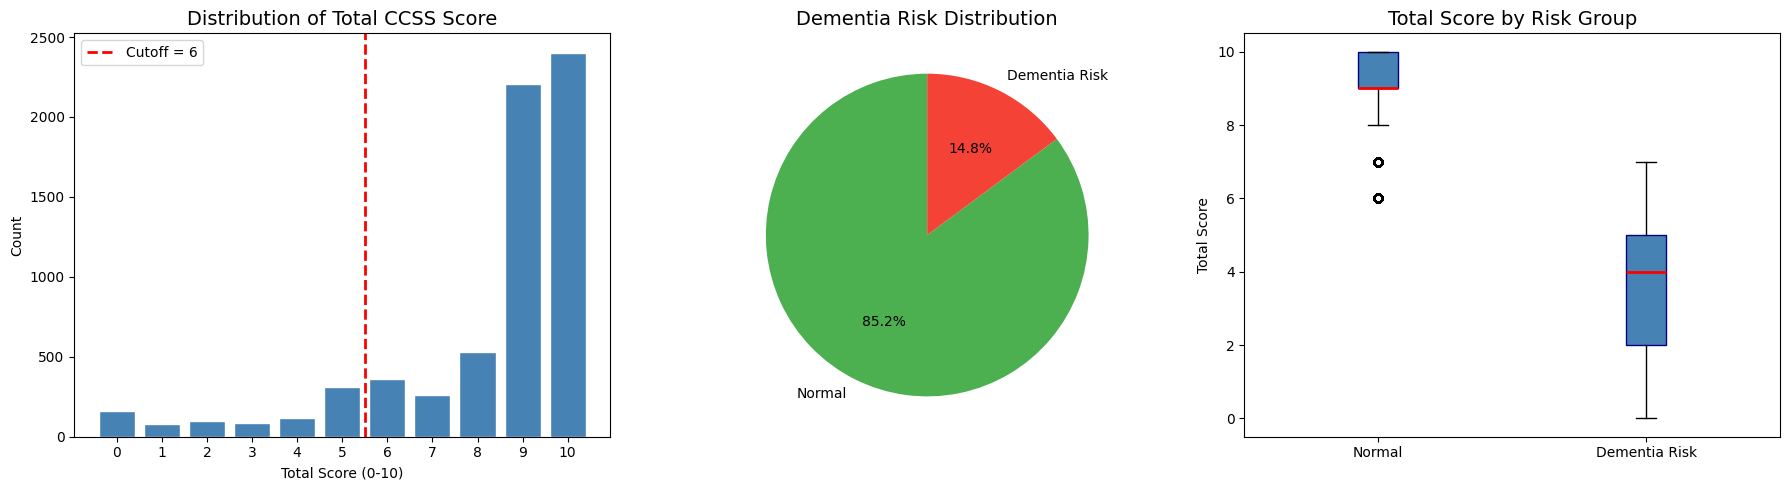

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

plt.rcParams['font.family'] = 'DejaVu Sans'

# กราฟ 1: distribution คะแนนรวม
axes[0].hist(df['total_score'], bins=11, range=(-0.5, 10.5),
             color='steelblue', edgecolor='white', rwidth=0.8)
axes[0].axvline(x=5.5, color='red', linestyle='--',
                linewidth=2, label='Cutoff = 6')
axes[0].set_title('Distribution of Total CCSS Score', fontsize=14)
axes[0].set_xlabel('Total Score (0-10)')
axes[0].set_ylabel('Count')
axes[0].set_xticks(range(0, 11))
axes[0].legend()

# กราฟ 2: dementia vs normal
counts = df['dementia_risk'].value_counts().sort_index()
axes[1].pie(
    counts.values,
    labels=['Normal', 'Dementia Risk'],
    autopct='%1.1f%%',
    colors=['#4CAF50', '#F44336'],
    startangle=90
)
axes[1].set_title('Dementia Risk Distribution', fontsize=14)

normal_scores = df[~df['dementia_risk']]['total_score']
risk_scores   = df[df['dementia_risk']]['total_score']

axes[2].boxplot(
    [normal_scores, risk_scores],
    labels=['Normal', 'Dementia Risk'],
    patch_artist=True,
    boxprops=dict(facecolor='steelblue', color='navy'),
    medianprops=dict(color='red', linewidth=2)
)
axes[2].set_title('Total Score by Risk Group', fontsize=14)
axes[2].set_ylabel('Total Score')

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/CDT_Dataset/EDA_distribution.png',
            dpi=150, bbox_inches='tight')
plt.show()

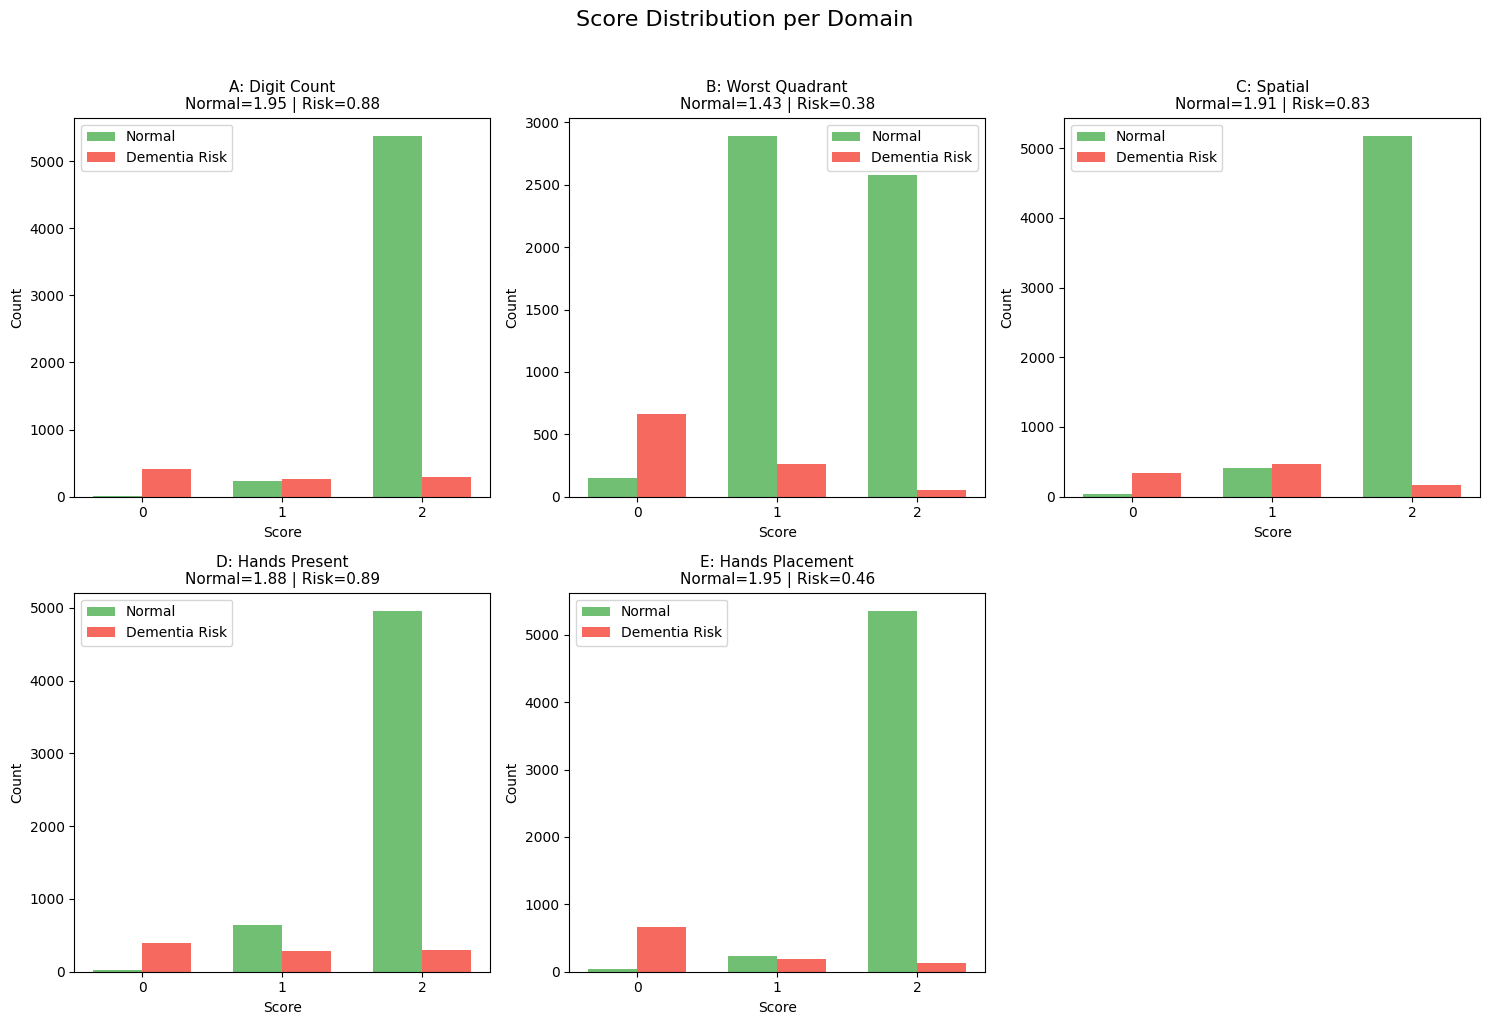

In [ ]:
domains = ['domain_A', 'domain_B', 'domain_C', 'domain_D', 'domain_E']
domain_names = ['A: Digit Count', 'B: Worst Quadrant',
                'C: Spatial', 'D: Hands Present', 'E: Hands Placement']

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

for i, (domain, name) in enumerate(zip(domains, domain_names)):
    normal = df[~df['dementia_risk']][domain].value_counts().sort_index()
    risk   = df[df['dementia_risk']][domain].value_counts().sort_index()

    x = np.array([0, 1, 2])
    width = 0.35

    axes[i].bar(x - width/2,
                [normal.get(j, 0) for j in [0,1,2]],
                width, label='Normal', color='#4CAF50', alpha=0.8)
    axes[i].bar(x + width/2,
                [risk.get(j, 0) for j in [0,1,2]],
                width, label='Dementia Risk', color='#F44336', alpha=0.8)

    mean_normal = df[~df['dementia_risk']][domain].mean()
    mean_risk   = df[df['dementia_risk']][domain].mean()

    axes[i].set_title(
        f'{name}\nNormal={mean_normal:.2f} | Risk={mean_risk:.2f}',
        fontsize=11
    )
    axes[i].set_xlabel('Score')
    axes[i].set_ylabel('Count')
    axes[i].set_xticks([0, 1, 2])
    axes[i].legend()

axes[5].axis('off')

plt.suptitle('Score Distribution per Domain', fontsize=16, y=1.02)
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/CDT_Dataset/EDA_domains.png',
            dpi=150, bbox_inches='tight')
plt.show()

/tmp/ipykernel_1287/3982956553.py:23: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(['A','B','C','D','E','Total'])


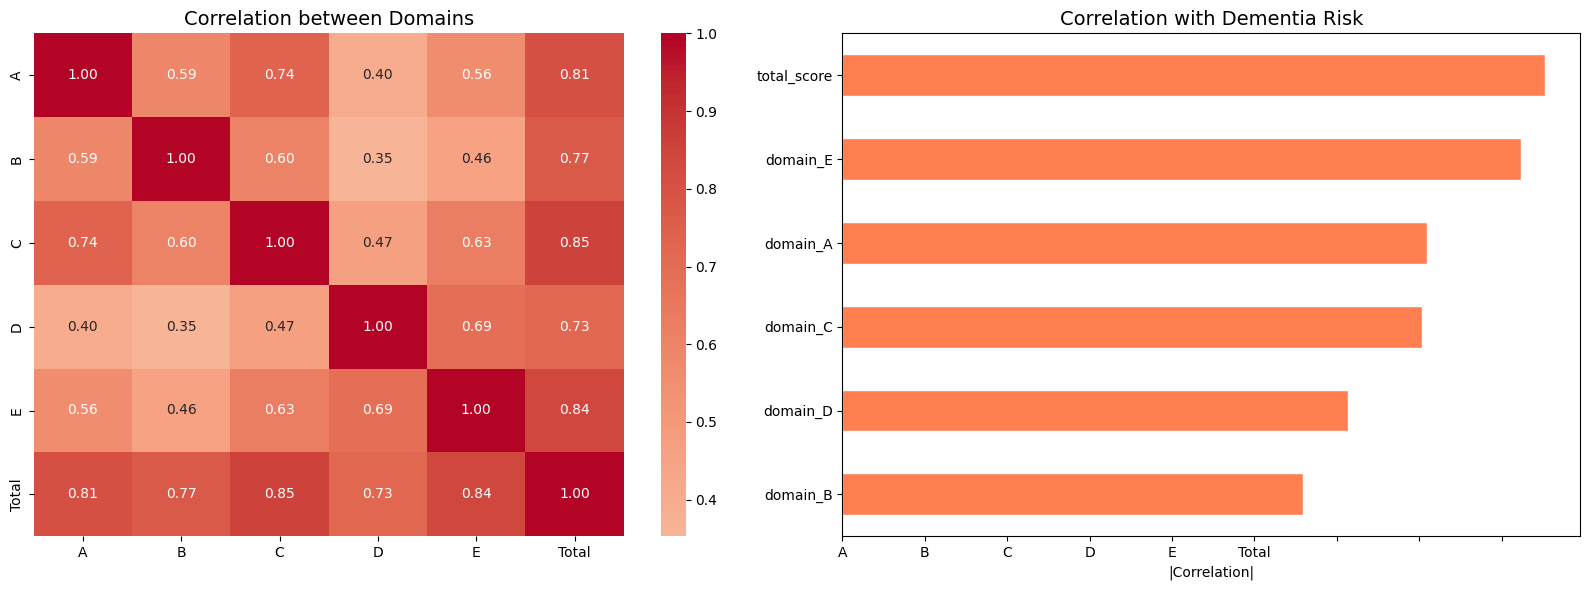


Domain ที่สัมพันธ์กับ Dementia มากที่สุด:
total_score    0.852584
domain_E       0.823939
domain_A       0.709764
domain_C       0.703097
domain_D       0.613731
domain_B       0.558951
dtype: float64


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Correlation ระหว่าง domain
corr_cols = domains + ['total_score']
corr = df[corr_cols].corr()

sns.heatmap(corr, annot=True, fmt='.2f',
            cmap='coolwarm', center=0,
            ax=axes[0],
            xticklabels=['A','B','C','D','E','Total'],
            yticklabels=['A','B','C','D','E','Total'])
axes[0].set_title('Correlation between Domains', fontsize=14)

# Domain ไหนสำคัญที่สุด (correlation กับ dementia_risk)
corr_with_risk = df[domains + ['total_score']].corrwith(
    df['dementia_risk'].astype(int)
).abs().sort_values(ascending=True)

corr_with_risk.plot(kind='barh', ax=axes[1],
                    color='coral', edgecolor='white')
axes[1].set_title('Correlation with Dementia Risk', fontsize=14)
axes[1].set_xlabel('|Correlation|')
axes[1].set_xticklabels(['A','B','C','D','E','Total'])

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/CDT_Dataset/EDA_correlation.png',
            dpi=150, bbox_inches='tight')
plt.show()

print('\nDomain ที่สัมพันธ์กับ Dementia มากที่สุด:')
print(corr_with_risk.sort_values(ascending=False))

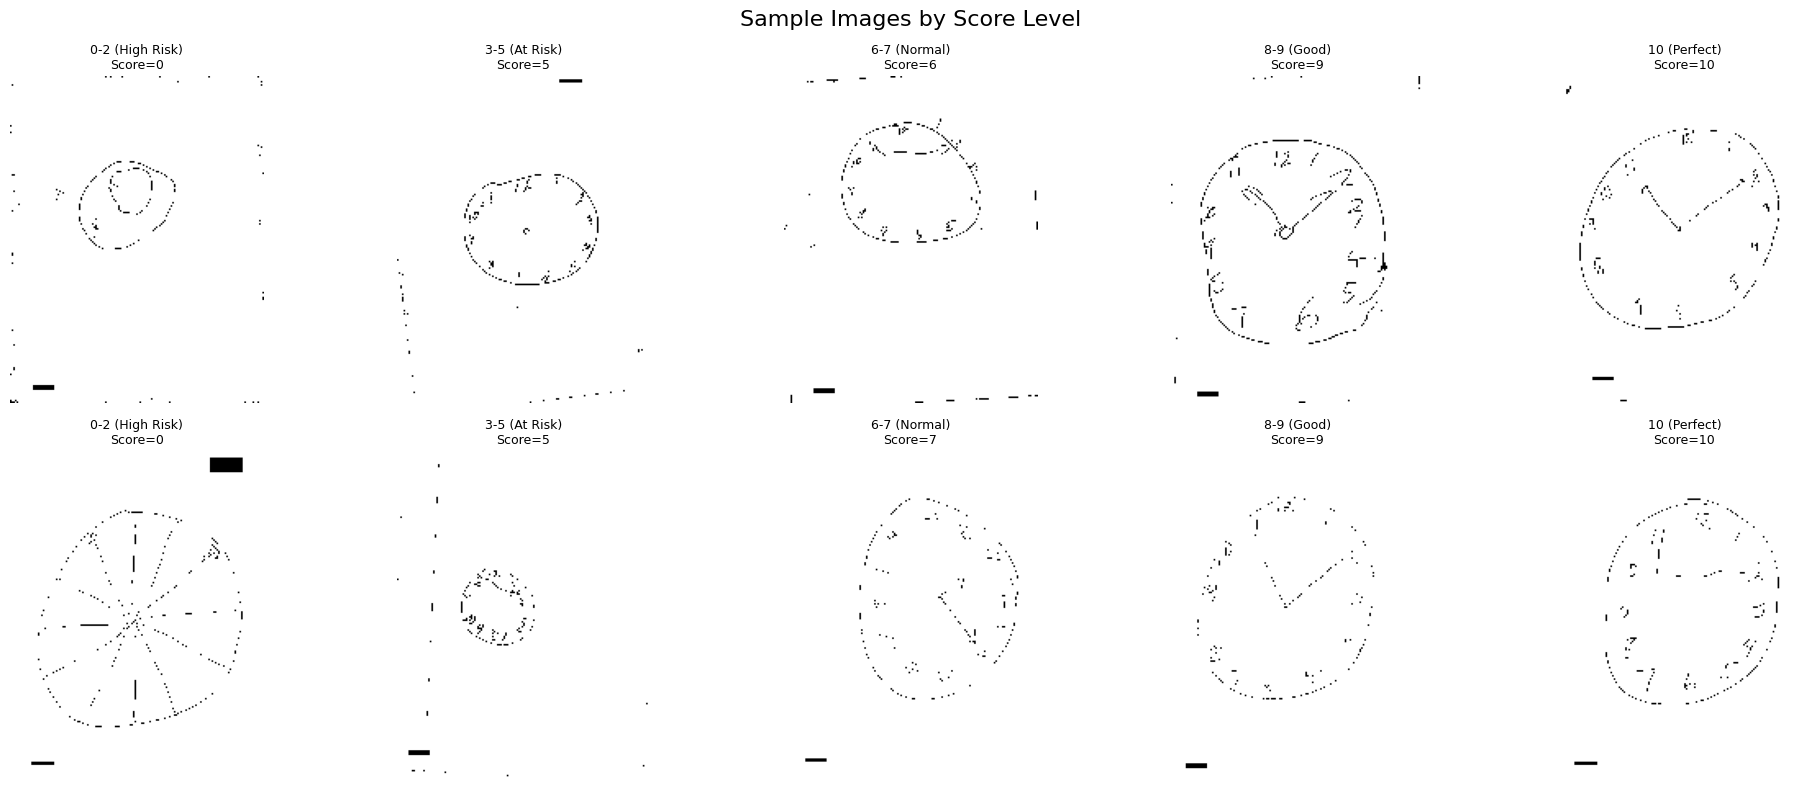

In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(20, 8))

score_groups = {
    '0-2 (High Risk)':  df[df['total_score'] <= 2],
    '3-5 (At Risk)':    df[(df['total_score'] >= 3) & (df['total_score'] <= 5)],
    '6-7 (Normal)':     df[(df['total_score'] >= 6) & (df['total_score'] <= 7)],
    '8-9 (Good)':       df[(df['total_score'] >= 8) & (df['total_score'] <= 9)],
    '10 (Perfect)':     df[df['total_score'] == 10],
}

for col, (group_name, group_df) in enumerate(score_groups.items()):
    for row in range(2):
        ax = axes[row][col]
        if len(group_df) > row:
            sample = group_df.iloc[row]
            img_path = f'{IMAGE_FOLDER}/{sample["filename"]}'
            try:
                img = Image.open(img_path)
                img.thumbnail((200, 200))
                ax.imshow(img, cmap='gray')
                ax.set_title(
                    f'{group_name}\nScore={sample["total_score"]}',
                    fontsize=9
                )
            except:
                ax.text(0.5, 0.5, 'ไม่พบรูป',
                        ha='center', va='center')
        else:
            ax.text(0.5, 0.5, 'ไม่มีข้อมูล',
                    ha='center', va='center')
        ax.axis('off')

plt.suptitle('Sample Images by Score Level', fontsize=16)
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/CDT_Dataset/EDA_examples.png',
            dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
normal_count = (~df['dementia_risk']).sum()
risk_count   = df['dementia_risk'].sum()
ratio        = normal_count / risk_count

domains = ['domain_A', 'domain_B', 'domain_C', 'domain_D', 'domain_E']
domain_names = ['A: Digit Count', 'B: Worst Quadrant',
                'C: Spatial', 'D: Hands Present', 'E: Hands Placement']

# Class imbalance
print(f'Total images     : {len(df)}')
print(f'Dementia Risk    : {df["dementia_risk"].sum()} ({df["dementia_risk"].mean()*100:.1f}%)')
print(f'Normal           : {(~df["dementia_risk"]).sum()} ({(~df["dementia_risk"]).mean()*100:.1f}%)')
print(f'Mean score       : {df["total_score"].mean():.2f}')

print(f'\nClass Balance:')
print(f'  Normal         : {normal_count}')
print(f'  Dementia Risk  : {risk_count}')
print(f'  Ratio          : {ratio:.1f}:1')

if ratio > 3:
    print(f'\nWarning: Imbalanced dataset (ratio {ratio:.1f}:1)')
    print('  Recommend: use class_weight or oversampling')
else:
    print(f'\nDataset is relatively balanced')

# Domain ที่อ่อนที่สุด
print(f'\nMean score per domain:')
for domain, name in zip(domains, domain_names):
    mean = df[domain].mean()
    bar = '|' * int(mean * 10)
    print(f'  {name}: {mean:.2f} {bar}')

# Confidence distribution
print(f'\nConfidence:')
print(f'  High (>=0.85)    : {(df["confidence"] >= 0.85).sum()}')
print(f'  Medium (0.7-0.84): {((df["confidence"] >= 0.7) & (df["confidence"] < 0.85)).sum()}')
print(f'  Low (<0.7)       : {(df["confidence"] < 0.7).sum()}')

Total images     : 6602
Dementia Risk    : 980 (14.8%)
Normal           : 5622 (85.2%)
Mean score       : 8.28

Class Balance:
  Normal         : 5622
  Dementia Risk  : 980
  Ratio          : 5.7:1

  Recommend: use class_weight or oversampling

Mean score per domain:
  A: Digit Count: 1.79 |||||||||||||||||
  B: Worst Quadrant: 1.28 ||||||||||||
  C: Spatial: 1.75 |||||||||||||||||
  D: Hands Present: 1.73 |||||||||||||||||
  E: Hands Placement: 1.72 |||||||||||||||||

Confidence:
  High (>=0.85)    : 5781
  Medium (0.7-0.84): 515
  Low (<0.7)       : 306


In [ ]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

# คำนวณ class weight
labels_array = df['dementia_risk'].astype(int).values

weights = compute_class_weight(
    class_weight='balanced',
    classes=np.array([0, 1]),
    y=labels_array
)

class_weights = {0: round(weights[0], 4),
                 1: round(weights[1], 4)}

print('='*40)
print('Class Weights for Training')
print('='*40)
print(f'Normal (0)       : {class_weights[0]}')
print(f'Dementia Risk (1): {class_weights[1]}')
print(f'\nRatio: 1:{class_weights[1]/class_weights[0]:.1f}')
print('\nSave these values for training notebook!')

import json
with open('/content/drive/MyDrive/CDT_Dataset/class_weights.json', 'w') as f:
    json.dump(class_weights, f)

Class Weights for Training
Normal (0)       : 0.5872
Dementia Risk (1): 3.3684

Ratio: 1:5.7

Save these values for training notebook!


In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

BASE     = '/content/drive/MyDrive/CDT_Dataset'
train_df = pd.read_csv(f'{BASE}/labels/human_train.csv')
val_df   = pd.read_csv(f'{BASE}/labels/human_val.csv')
test_df  = pd.read_csv(f'{BASE}/labels/human_test.csv')

all_df = pd.concat(
    [train_df, val_df, test_df]
).reset_index(drop=True)

print(f'Total: {len(all_df)} รูป')
print(f'Train: {len(train_df)}')
print(f'Val  : {len(val_df)}')
print(f'Test : {len(test_df)}')
print()
print('Class distribution:')
for col in ['domain_A','domain_B',
            'domain_C','domain_D','domain_E']:
    counts = all_df[col].value_counts().sort_index()
    print(f'\n{col}:')
    for cls, n in counts.items():
        pct = n/len(all_df)*100
        print(f'  class {cls}: {n} ({pct:.1f}%)')

print()
dementia = (all_df[[
    'domain_A','domain_B','domain_C',
    'domain_D','domain_E'
]].sum(axis=1) < 6).sum()
print(f'Dementia risk: {dementia} ({dementia/len(all_df)*100:.1f}%)')
print(f'Normal       : {len(all_df)-dementia} ({(len(all_df)-dementia)/len(all_df)*100:.1f}%)')

Total: 6602 รูป
Train: 4621
Val  : 653
Test : 1328

Class distribution:

domain_A:
  class 0: 560 (8.5%)
  class 1: 319 (4.8%)
  class 2: 5723 (86.7%)

domain_B:
  class 0: 1001 (15.2%)
  class 1: 3047 (46.2%)
  class 2: 2554 (38.7%)

domain_C:
  class 0: 637 (9.6%)
  class 1: 611 (9.3%)
  class 2: 5354 (81.1%)

domain_D:
  class 0: 710 (10.8%)
  class 1: 2342 (35.5%)
  class 2: 3550 (53.8%)

domain_E:
  class 0: 1162 (17.6%)
  class 1: 753 (11.4%)
  class 2: 4687 (71.0%)

Dementia risk: 1117 (16.9%)
Normal       : 5485 (83.1%)


In [6]:
BASE          = '/content/drive/MyDrive/CDT_Dataset'
HUMAN_FOLDER  = f'{BASE}/images_human_fixed'
RESULT_FOLDER = f'{BASE}/results'

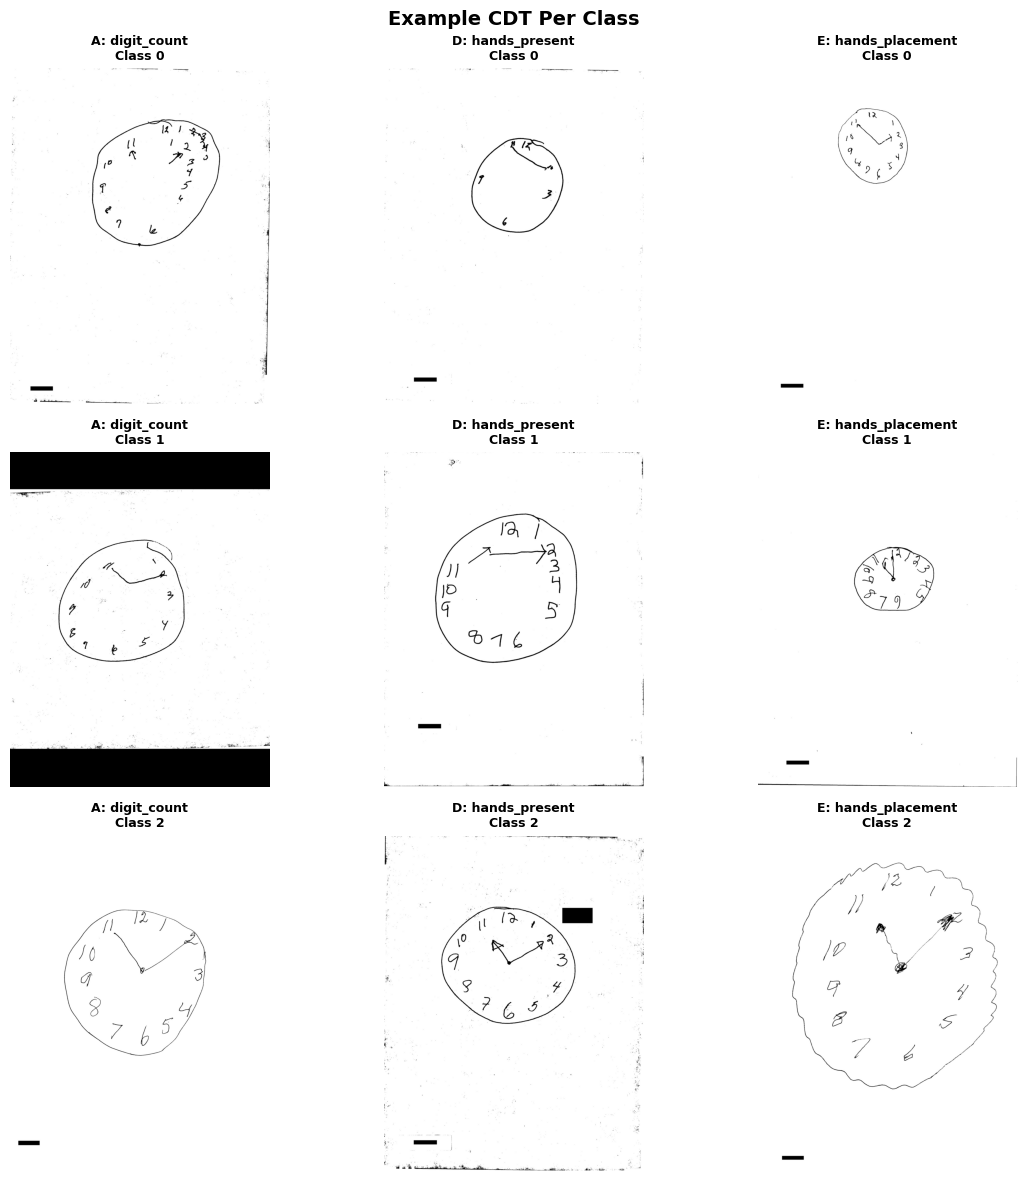

In [8]:
import matplotlib
matplotlib.rcParams['font.family'] = 'DejaVu Sans'
from PIL import Image
import random

fig, axes = plt.subplots(
    3, 3, figsize=(12, 12)
)

domains = ['domain_A', 'domain_D', 'domain_E']
domain_labels = [
    'A: digit_count',
    'D: hands_present',
    'E: hands_placement'
]

all_df['total'] = all_df[[
    'domain_A','domain_B','domain_C',
    'domain_D','domain_E'
]].sum(axis=1)
all_df['dementia_risk'] = all_df['total'] < 6

for col_idx, (domain, label) in enumerate(
    zip(domains, domain_labels)
):
    for row_idx, cls in enumerate([0, 1, 2]):
        subset = all_df[
            all_df[domain] == cls
        ]['filename'].tolist()

        if not subset:
            axes[row_idx][col_idx].axis('off')
            continue

        fname = random.choice(subset)
        try:
            img = Image.open(
                f'{HUMAN_FOLDER}/{fname}'
            ).convert('RGB')
            axes[row_idx][col_idx].imshow(img)
        except:
            axes[row_idx][col_idx].axis('off')
            continue

        axes[row_idx][col_idx].set_title(
            f'{label}\nClass {cls}',
            fontsize=9, fontweight='bold'
        )
        axes[row_idx][col_idx].axis('off')

plt.suptitle(
    'Example CDT Per Class',
    fontsize=14, fontweight='bold'
)
plt.tight_layout()
plt.savefig(
    f'{RESULT_FOLDER}/eda_examples.png',
    dpi=150, bbox_inches='tight'
)
plt.show()

In [10]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import os
from PIL import Image
import random

BASE          = '/content/drive/MyDrive/CDT_Dataset'
HUMAN_FOLDER  = f'{BASE}/images_human_fixed'
RESULT_FOLDER = f'{BASE}/results'

os.makedirs(RESULT_FOLDER, exist_ok=True)

train_df = pd.read_csv(f'{BASE}/labels/human_train.csv')
val_df   = pd.read_csv(f'{BASE}/labels/human_val.csv')
test_df  = pd.read_csv(f'{BASE}/labels/human_test.csv')

all_df = pd.concat(
    [train_df, val_df, test_df]
).reset_index(drop=True)

all_df['total_score'] = all_df[[
    'domain_A','domain_B','domain_C',
    'domain_D','domain_E'
]].sum(axis=1)
all_df['dementia_risk'] = all_df['total_score'] < 6

print(f'Total: {len(all_df)} รูป')
print(f'Train: {len(train_df)}')
print(f'Val  : {len(val_df)}')
print(f'Test : {len(test_df)}')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Total: 6602 รูป
Train: 4621
Val  : 653
Test : 1328


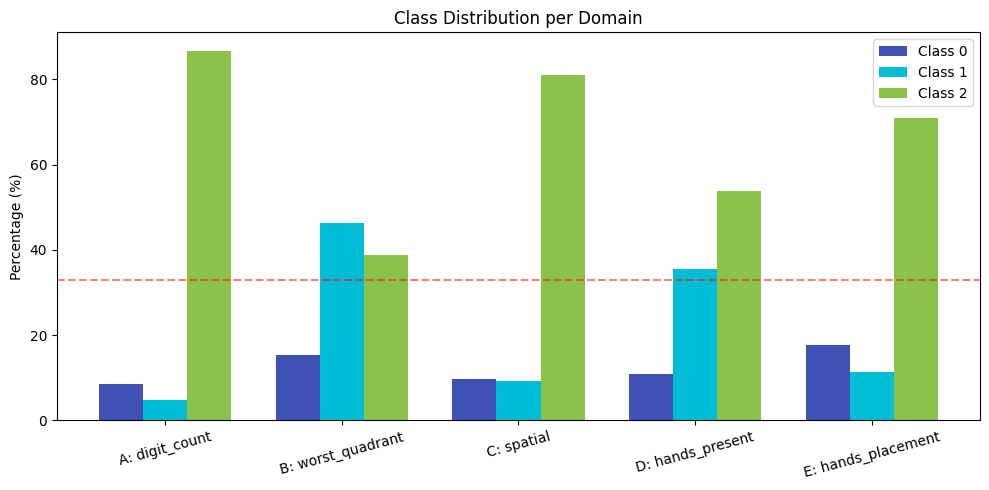

In [11]:
import matplotlib.pyplot as plt
import numpy as np

domains    = ['A','B','C','D','E']
class0_pct = [8.5, 15.2, 9.6, 10.8, 17.6]
class1_pct = [4.8, 46.2, 9.3, 35.5, 11.4]
class2_pct = [86.7, 38.7, 81.1, 53.8, 71.0]

x   = np.arange(len(domains))
w   = 0.25
fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(x-w, class0_pct, w, label='Class 0', color='#3F51B5')
ax.bar(x,   class1_pct, w, label='Class 1', color='#00BCD4')
ax.bar(x+w, class2_pct, w, label='Class 2', color='#8BC34A')

ax.set_xticks(x)
ax.set_xticklabels([
    'A: digit_count', 'B: worst_quadrant',
    'C: spatial', 'D: hands_present',
    'E: hands_placement'
], rotation=15)
ax.set_ylabel('Percentage (%)')
ax.set_title('Class Distribution per Domain')
ax.legend()
ax.axhline(y=33, color='red', linestyle='--',
           alpha=0.5, label='Balanced (33%)')
plt.tight_layout()
plt.savefig(f'{RESULT_FOLDER}/eda_class_dist.png',
            dpi=150)
plt.show()

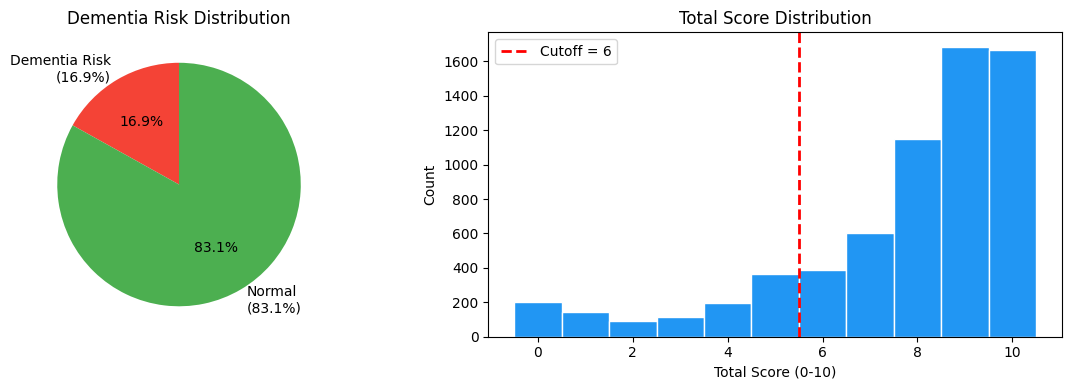

In [12]:
all_df['total_score'] = all_df[[
    'domain_A','domain_B','domain_C',
    'domain_D','domain_E'
]].sum(axis=1)

all_df['dementia_risk'] = all_df['total_score'] < 6

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sizes  = [1117, 5485]
labels = ['Dementia Risk\n(16.9%)',
          'Normal\n(83.1%)']
colors = ['#F44336', '#4CAF50']
axes[0].pie(sizes, labels=labels,
            colors=colors, autopct='%1.1f%%',
            startangle=90)
axes[0].set_title('Dementia Risk Distribution')

axes[1].hist(
    all_df['total_score'],
    bins=11, range=(-0.5, 10.5),
    color='#2196F3', edgecolor='white'
)
axes[1].axvline(x=5.5, color='red',
                linestyle='--', linewidth=2,
                label='Cutoff = 6')
axes[1].set_xlabel('Total Score (0-10)')
axes[1].set_ylabel('Count')
axes[1].set_title('Total Score Distribution')
axes[1].legend()

plt.tight_layout()
plt.savefig(f'{RESULT_FOLDER}/eda_dementia_dist.png',
            dpi=150)
plt.show()

In [13]:
print('Accuracy ถ้าเดา class 2 ตลอด:')
for col, pct in zip(
    ['A','B','C','D','E'],
    [86.7, 38.7, 81.1, 53.8, 71.0]
):
    bar = '█' * int(pct/5)
    print(f'Domain {col}: {pct:5.1f}% {bar}')

Accuracy ถ้าเดา class 2 ตลอด:
Domain A:  86.7% █████████████████
Domain B:  38.7% ███████
Domain C:  81.1% ████████████████
Domain D:  53.8% ██████████
Domain E:  71.0% ██████████████


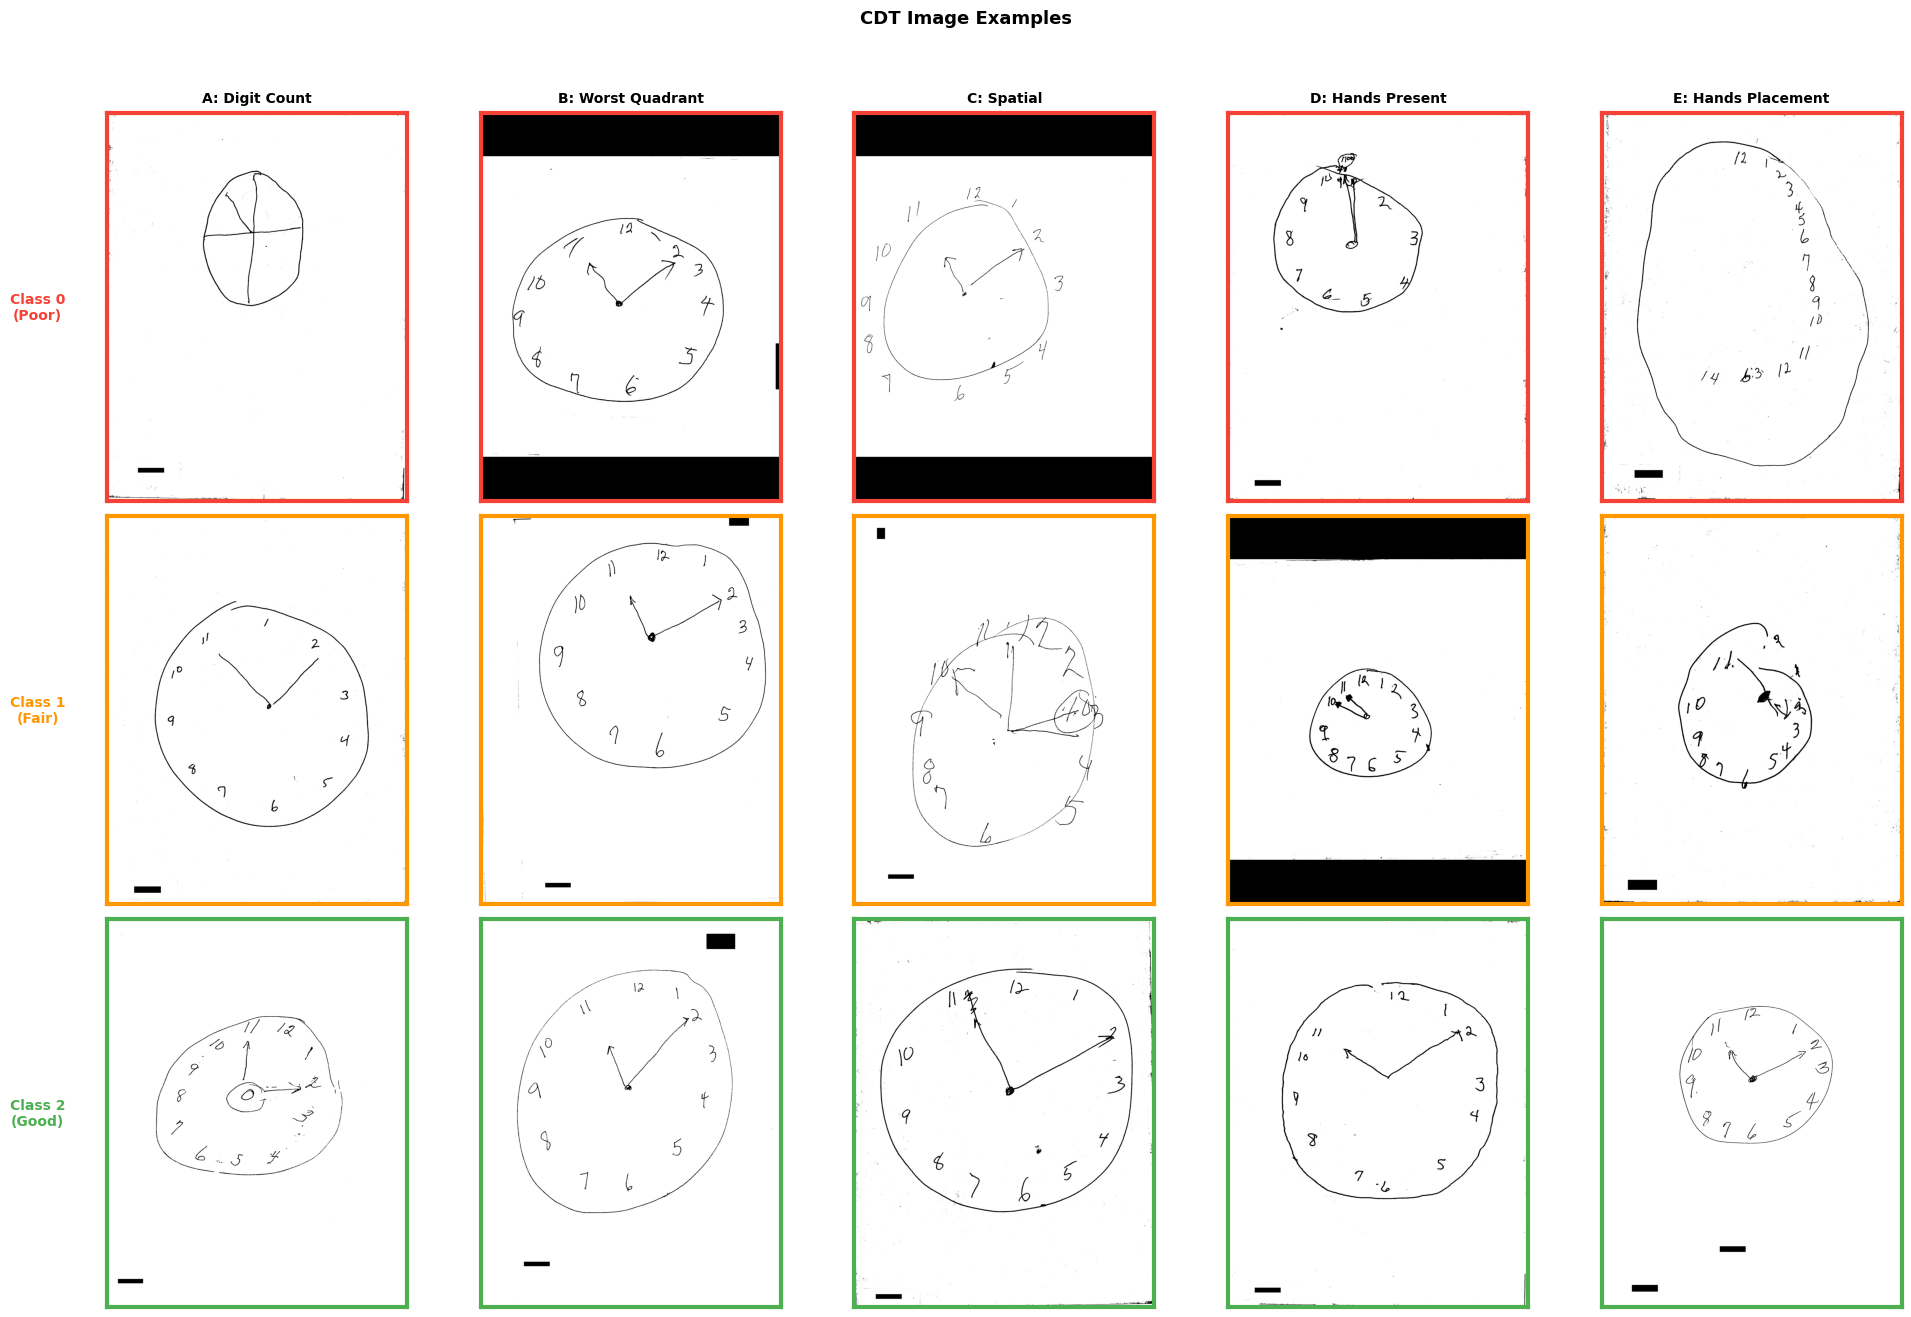

In [14]:
import matplotlib.pyplot as plt
from PIL import Image
import random

fig, axes = plt.subplots(
    3, 5, figsize=(20, 13)
)

domains = [
    ('domain_A', 'A: Digit Count'),
    ('domain_B', 'B: Worst Quadrant'),
    ('domain_C', 'C: Spatial'),
    ('domain_D', 'D: Hands Present'),
    ('domain_E', 'E: Hands Placement'),
]

class_labels = {
    0: 'Class 0\n(Poor)',
    1: 'Class 1\n(Fair)',
    2: 'Class 2\n(Good)',
}
class_colors = {
    0: '#F44336',
    1: '#FF9800',
    2: '#4CAF50',
}

for col_idx, (domain, label) in enumerate(domains):
    for row_idx, cls in enumerate([0, 1, 2]):
        ax = axes[row_idx][col_idx]

        subset = all_df[
            all_df[domain] == cls
        ]['filename'].tolist()

        img_loaded = False
        random.shuffle(subset)

        for fname in subset[:10]:
            try:
                img = Image.open(
                    f'{HUMAN_FOLDER}/{fname}'
                ).convert('RGB')
                ax.imshow(img)
                img_loaded = True
                break
            except:
                continue

        if not img_loaded:
            ax.text(
                0.5, 0.5, 'No image',
                ha='center', va='center',
                transform=ax.transAxes
            )

        # title บนสุดของแต่ละ column
        if row_idx == 0:
            ax.set_title(
                label,
                fontsize=10,
                fontweight='bold',
                pad=8
            )

        # label ซ้ายสุดของแต่ละ row
        if col_idx == 0:
            ax.set_ylabel(
                class_labels[cls],
                fontsize=10,
                fontweight='bold',
                color=class_colors[cls],
                rotation=0,
                labelpad=50,
                va='center'
            )

        # กรอบสี
        for spine in ax.spines.values():
            spine.set_edgecolor(class_colors[cls])
            spine.set_linewidth(3)

        ax.set_xticks([])
        ax.set_yticks([])

plt.suptitle(
    'CDT Image Examples\n',
    fontsize=13, fontweight='bold', y=1.01
)
plt.tight_layout()
plt.savefig(
    f'{RESULT_FOLDER}/eda_examples_all_domains.png',
    dpi=150, bbox_inches='tight'
)
plt.show()